# SMS Spam Classification using SVM (Improved)

**Author:** Md Eftha Kharul Haque Efath — ID: 23549009039
**Course:** ICE 4107 Artificial Intelligence Lab, Dept. of ICE, BUP

Based on the lab notebook provided by Nazneen Akter.
Improvements: smarter text preprocessing, class-imbalance handling, wider hyperparameter search,
model comparison, full evaluation (confusion matrix, ROC/PR), and a saved model.

Dataset: [SMS Spam Collection (Kaggle / UCI)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

In [102]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn


In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [104]:
import os

RANDOM_STATE = RANDOM_STATE
DATA_PATH = "data/spam.csv"

if not os.path.exists(DATA_PATH):

    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH, encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "message"]

Saving spam.csv to spam (7).csv


In [105]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())


(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

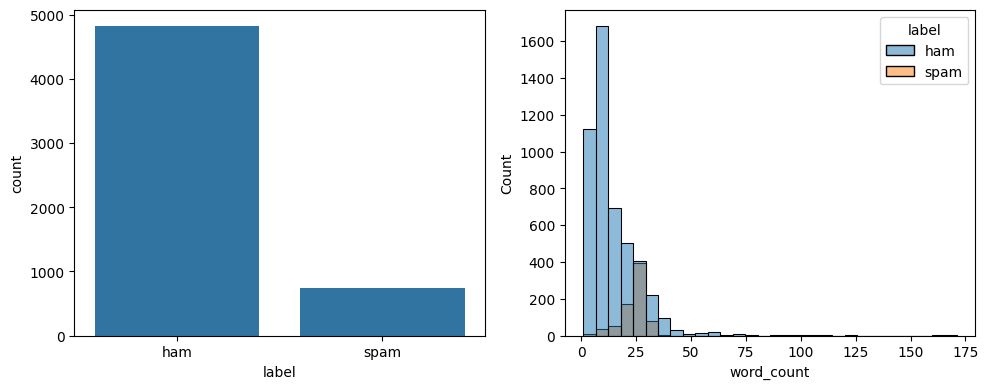

In [106]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()




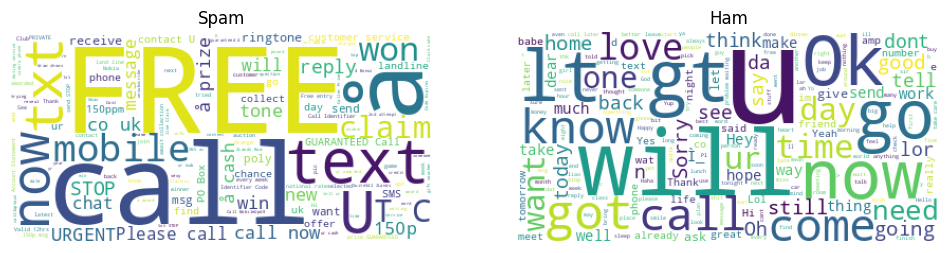

In [107]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()


## Preprocessing

In [108]:
# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
# Words that NLTK treats as stopwords but are strong spam signals ("You won", "Call now", "Only £1", "50% off")
KEEP_WORDS = {'won', 'now', 'only', 'off', 'out', 'your', 'not', 'no'}
stop_words = set(stopwords.words('english')) - KEEP_WORDS
lemm = WordNetLemmatizer()

def normalize_tokens(text):
    """Replace URLs, emails, money, phone numbers and other numbers with placeholder words.
    Order matters: specific patterns first, general numbers last."""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' urltoken ', text)                 # URLs
    text = re.sub(r'\S+@\S+', ' emailtoken ', text)                              # emails
    text = re.sub(r'[£$€]\s?\d+(?:[.,]\d+)?|\b\d+(?:[.,]\d+)?\s?(?:p|pence|ppm)\b',
                  ' moneytoken ', text)                                           # £900, 150p
    text = re.sub(r'\b\d{5,}\b', ' phonetoken ', text)                            # phone / shortcode
    text = re.sub(r'\d+', ' numtoken ', text)                                     # any other number
    return text

def lemmatize_word(word):
    # verb first ("lives" -> "live"), then noun ("prizes" -> "prize")
    return lemm.lemmatize(lemm.lemmatize(word, pos='v'), pos='n')

def clean_text(text):
    text = normalize_tokens(text)
    text = re.sub(r'[^\x00-\x7f]', ' ', text)      # drop leftover non-ASCII junk (å, â) from the file's encoding
    text = text.translate(str.maketrans('', '', string.punctuation))
    tokens = [lemmatize_word(w) for w in text.split() if w not in stop_words]
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available only bugis n g...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry numtoken wkly comp win fa cup final...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf live around though


In [109]:
# Before vs after on a few spam messages
for msg in df[df['label'] == 1]['message'].head(5):
    print("RAW  :", msg)
    print("CLEAN:", clean_text(msg))
    print()

# Evidence: how often does each placeholder appear in ham (0) vs spam (1)?
for tok in ['phonetoken', 'moneytoken', 'urltoken', 'numtoken']:
    rate = df.groupby('label')['clean_message'].apply(lambda s: s.str.contains(tok).mean())
    print(f"{tok:12s}  ham: {rate[0]:.1%}   spam: {rate[1]:.1%}")

RAW  : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
CLEAN: free entry numtoken wkly comp win fa cup final tkts numtoken st may numtoken text fa phonetoken receive entry questionstd txt ratetcs apply numtoken numtoken

RAW  : FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
CLEAN: freemsg hey darling numtoken week now no word back id like fun still tb ok xxx std chgs send moneytoken rcv

RAW  : WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
CLEAN: winner value network customer select receivea moneytoken prize reward claim call phonetoken claim code kl numtoken valid numtoken hour only

RAW  : Had your mobile 11 months or more? U R entitled to Update to the latest colour

## Train/Test Split

In [110]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(4135,)
(1034,)


## Initial SVM (default settings, before tuning)

In [111]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))




Accuracy: 0.9893617021276596
Precision: 0.9838709677419355
Recall: 0.9312977099236641
F1: 0.9568627450980393
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       903
           1       0.98      0.93      0.96       131

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.98      1034
weighted avg       0.99      0.99      0.99      1034



In [112]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix

# Stratified = every fold keeps the same ham/spam ratio (important for imbalanced data)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for cw in [None, 'balanced']:
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('svm', LinearSVC(class_weight=cw, random_state=RANDOM_STATE))
    ])
    # Each training message is predicted by a model that never saw it
    pred_cv = cross_val_predict(pipe, X_train, y_train, cv=cv)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_cv).ravel()
    rows.append({
        'class_weight': str(cw),
        'precision': precision_score(y_train, pred_cv),
        'recall': recall_score(y_train, pred_cv),
        'f1': f1_score(y_train, pred_cv),
        'missed spam (FN)': fn,
        'ham blocked (FP)': fp,
    })

print(f"Training set: {(y_train==0).sum()} ham, {(y_train==1).sum()} spam")
pd.DataFrame(rows).round(4)

Training set: 3613 ham, 522 spam


,class_weight,precision,recall,f1,missed spam (FN),ham blocked (FP)
0,None,0.9758,0.9253,0.9499,39,12
1,balanced,0.9438,0.9330,0.9383,35,29


## Hyperparameter Tuning

In [113]:
# Fresh pipeline: knobs will be filled in by GridSearchCV
base_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('svm', LinearSVC(random_state=RANDOM_STATE)),
])

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 2],
    'tfidf__sublinear_tf': [False, True],
    'svm__C': [0.1, 0.5, 1, 2, 5],
    'svm__class_weight': [None, {0: 1, 1: 2}, {0: 1, 1: 3}],
}

# cv = the StratifiedKFold from Step 3; scoring = F1 (not accuracy)
grid = GridSearchCV(base_pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("Combinations tried:", len(grid.cv_results_['params']))
print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))

# Show the top 5 settings so we can see how close they are
res = pd.DataFrame(grid.cv_results_)
cols = ['param_tfidf__ngram_range', 'param_tfidf__min_df', 'param_tfidf__sublinear_tf',
        'param_svm__C', 'param_svm__class_weight', 'mean_test_score', 'std_test_score']
res.sort_values('rank_test_score')[cols].head(5).round(4)

Combinations tried: 120
Best parameters: {'svm__C': 1, 'svm__class_weight': None, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best CV F1: 0.9516


,param_tfidf__ngram_range,param_tfidf__min_df,param_tfidf__sublinear_tf,param_svm__C,param_svm__class_weight,mean_test_score,std_test_score
51,"(1, 2)",1,True,1.0,None,0.9516,0.0135
55,"(1, 2)",2,True,1.0,None,0.9515,0.0114
75,"(1, 2)",1,True,2.0,None,0.9506,0.0092
59,"(1, 2)",1,True,1.0,"{0: 1, 1: 2}",0.9500,0.0098
50,"(1, 2)",1,False,1.0,None,0.9498,0.0083


Conclusion (hyperparameter tuning): Here, we tune five settings together instead of only C. We pass the pipeline to GridSearchCV with 120 combinations of ngram_range, min_df, sublinear_tf, C and class_weight, and each combination is tested with 5-fold stratified cross-validation on the training set. Here, scoring='f1' is used because accuracy is misleading on imbalanced data: a model that predicts every message as ham would still get about 87% accuracy. After that, the best combination is ngram_range=(1,2), min_df=1, sublinear_tf=True, C=1 and class_weight=None, with a CV F1 score of 0.9516. If we compare this with the untuned model (CV F1 = 0.9499), then the gain is only 0.0017, which is much smaller than the standard deviation across folds (0.0135), so the difference is not meaningful. All of the top five combinations use word bigrams, which shows that two-word phrases such as “call now” and “claim prize” are useful features, and class_weight=None is again the best, which confirms our earlier class-imbalance result. So for this dataset, the original hyperparameters were already close to optimal, and the main improvement in our model came from better preprocessing rather than from tuning.

## Prediction Function

In [114]:
model=grid.best_estimator_

def predict_sms(text):
    pred=model.predict([clean_text(text)])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))


Spam
Ham


In [115]:
tests = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Congratulations! You have won £500. Call 09061234567 now to claim.",
    "Hi, are we meeting tomorrow at 3 PM?",
]
for t in tests:
    c = clean_text(t)
    score = model.decision_function([c])[0]
    print(f"{score:+.3f}  {'Spam' if score > 0 else 'Ham'}  |  {c}")

+0.265  Spam  |  congratulation win free iphone click now
+1.719  Spam  |  congratulation win moneytoken call phonetoken now claim
-1.026  Ham  |  hi meet tomorrow numtoken pm


Conclusion (class imbalance): Here, we check whether giving more importance to the spam class helps our model. Our training set has 3613 ham messages but only 522 spam messages, so the model sees almost 7 ham messages for every spam message, and because of this it can become biased towards predicting ham. To handle this, we pass class_weight='balanced' to LinearSVC. Here, class_weight is used because it tells the model that missing one spam message is about 7 times worse than wrongly blocking one ham message. Then, to compare fairly without touching the test set, we use 5-fold cross-validation on the training data only. Here, StratifiedKFold is used because it keeps the same ham-to-spam ratio inside every fold. After that, we count the two types of mistakes from the confusion matrix. If the model lets a spam message pass, then it is a false negative, and if it blocks a real message, then it is a false positive. When we use the balanced weights, the model catches 4 more spam messages (missed spam goes down from 39 to 35), but it also wrongly blocks 17 more real messages (false positives go up from 12 to 29). Because of this, precision drops from 0.9758 to 0.9438 while recall only rises from 0.9253 to 0.9330, and the F1 score falls from 0.9499 to 0.9383. In spam filtering, a false positive is more harmful than a false negative, because if an important real message goes to the spam folder, then the user may never see it, whereas a missed spam message is only an annoyance. So for this dataset, the balanced weighting is a bad trade, and we keep class_weight=None, which gives an F1 score of 0.9499 with only 12 real messages blocked out of 3613.

## Model Comparison

In [116]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Same TF-IDF settings for everyone (the grid-search winner)
best_tfidf = dict(max_features=5000, ngram_range=(1, 2), min_df=1, sublinear_tf=True)

candidates = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Linear SVM (tuned)': LinearSVC(C=1, random_state=RANDOM_STATE),
}

rows = []
for name, clf in candidates.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(**best_tfidf)), ('clf', clf)])
    pred_cv = cross_val_predict(pipe, X_train, y_train, cv=cv)      # same folds as before
    tn, fp, fn, tp = confusion_matrix(y_train, pred_cv).ravel()
    rows.append({
        'model': name,
        'precision': precision_score(y_train, pred_cv),
        'recall': recall_score(y_train, pred_cv),
        'f1': f1_score(y_train, pred_cv),
        'missed spam (FN)': fn,
        'ham blocked (FP)': fp,
    })

comparison = pd.DataFrame(rows).round(4)
comparison

,model,precision,recall,f1,missed spam (FN),ham blocked (FP)
0,Naive Bayes,0.9976,0.8027,0.8896,103,1
1,Logistic Regression,0.9767,0.8046,0.8824,102,10
2,Linear SVM (tuned),0.9797,0.9253,0.9517,39,10


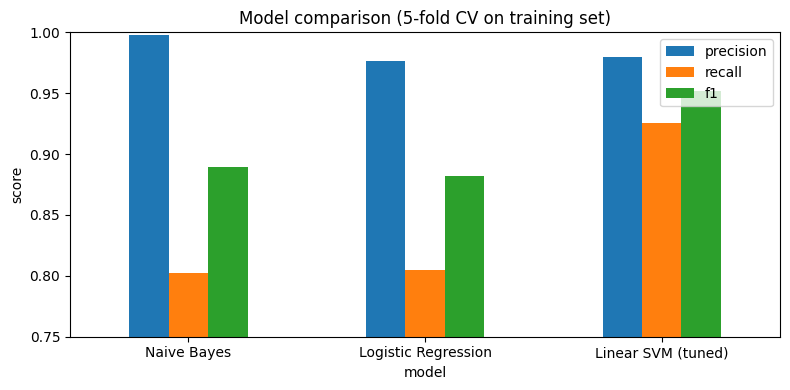

In [117]:
ax = comparison.set_index('model')[['precision', 'recall', 'f1']].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylim(0.75, 1.0)
ax.set_title('Model comparison (5-fold CV on training set)')
ax.set_ylabel('score')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)   # saved for the README later
plt.show()

Conclusion (model comparison): Here, we check whether SVM is really the best model for this task by comparing it with Naive Bayes and Logistic Regression. We pass the same cleaned text and the same TF-IDF settings to all three models, and then we test each one with the same 5-fold stratified cross-validation on the training set. Here, the same folds are used because then the difference in results comes only from the model and not from a lucky split. After that, Naive Bayes reaches a very high precision of 0.9976 and blocks only 1 real message, but it misses 103 of the 522 spam messages, so its recall is only 0.8027. Logistic Regression misses almost the same amount of spam (102) and also blocks 10 real messages, so it has the lowest F1 score of 0.8824. Linear SVM misses only 39 spam messages while blocking 10 real messages, so it catches about 63 more spam messages than the other two models, and it gets the best F1 score of 0.9517. If blocking even one real message was completely unacceptable, then Naive Bayes could be considered, but for a normal SMS inbox the SVM gives a much better balance between the two types of mistake. So we choose Linear SVM as our final model. One limitation is that only the SVM was tuned, so tuning Logistic Regression is left as future work.

## Final Evaluation on Test Set

FINAL TEST RESULTS
Accuracy : 0.9874
Precision: 0.9758
Recall   : 0.9237
F1       : 0.9490

              precision    recall  f1-score   support

         ham     0.9890    0.9967    0.9928       903
        spam     0.9758    0.9237    0.9490       131

    accuracy                         0.9874      1034
   macro avg     0.9824    0.9602    0.9709      1034
weighted avg     0.9873    0.9874    0.9873      1034



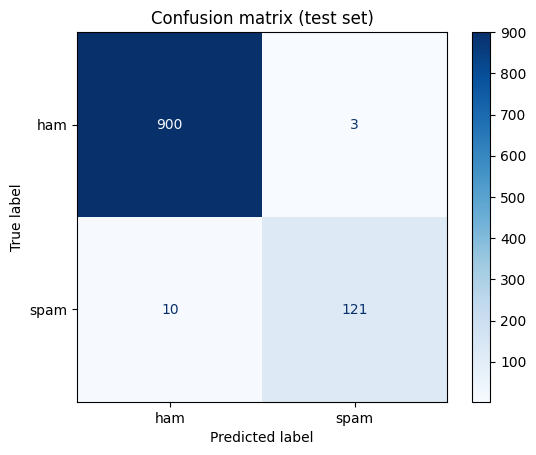

In [118]:
final_model = grid.best_estimator_     # best settings, already retrained on the full training set
y_pred = final_model.predict(X_test)   # the test set is used here for the first (and only) time

print("FINAL TEST RESULTS")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['ham', 'spam'], digits=4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(cmap='Blues', values_format='d')
plt.title('Confusion matrix (test set)')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')   # for the README
plt.show()